In dit script zit een fout!

De inputs worden opgedeeld in fracties, maar de outputs niet. Waardoor in de neural_network-functie de verkeerde inputs aan de verkeerde outputs worden gekoppeld.

Ook in de opdeling van de inputs in inputs_part zit ergens een fout.

In [213]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math
import time

In [5]:
def sigma(x):
    s = 1/(1 + np.exp(-x))
    return s

def sigma_der(x):
    s = np.exp(-x)/(1+np.exp(-x))**2
    return s

In [6]:
def det_activations(inputs, weights, biases):
    
    activations = []
    activations.append(np.dot(weights[0],inputs) + biases[0])
    
    for i in range(1,len(biases)):

        activations.append(np.dot(weights[i],activations[i-1]) + biases[i])

    activations = [sigma(act) for act in activations]
    activations = [np.round(act, 3) for act in activations]
        
    return activations

In [7]:
def grad(act, wt, bs, ins, outs):
    
    gr_act = [0*a for a in act]
    gr_bs = [0*b for b in bs]
    gr_wt = [0*w for w in wt]

    L = len(act)

    ind = []   
    for i in range(L):
        ind.append(list(range(len(act[i]))))


    for i in range(L-1): 
        for j in range(len(act[i])):
            gr_act[i][j] = sum([2 * (act[-1][k] - outs[k]) * sigma_der(np.dot(wt[-1][k], act[-2]) + bs[-1][k]) * (wt[-1][k][j] if i == L-2 
                else sum([wt[-1][k][l] * sigma_der(np.dot(wt[-2][l], act[-3]) + bs[-2][l]) * (wt[-2][l][j] if i == L-3 
                else sum([wt[-2][l][m] * sigma_der(np.dot(wt[-3][m], act[-4]) + bs[-3][m]) * (wt[-3][m][j] if i == L-4 
                else sum([wt[-3][m][n] * sigma_der(np.dot(wt[-4][n], act[-5]) + bs[-4][n]) * (wt[-4][n][j] if i == L-5 
                else sum([wt[-4][n][o] * sigma_der(np.dot(wt[-5][o], act[-6]) + bs[-5][o]) * (wt[-5][o][j] if i == L-6
                else sum([wt[-5][o][p] * sigma_der(np.dot(wt[-6][p], act[-7]) + bs[-6][p]) * (wt[-6][p][j] if i == L-7
                else sum([wt[-6][p][q] * sigma_der(np.dot(wt[-7][q], act[-8]) + bs[-7][q]) * (wt[-7][q][j] if i == L-8
                else sum([wt[-7][q][r] * sigma_der(np.dot(wt[-8][r], act[-9]) + bs[-8][r]) * (wt[-8][r][j] if i == L-9
                else sum([wt[-8][r][s] * sigma_der(np.dot(wt[-9][s], act[-10]) + bs[-9][s]) * (wt[-9][s][j] if i == L-10 
                else sum([wt[-9][s][t] * sigma_der(np.dot(wt[-10][t], act[-11]) + bs[-10][t]) * wt[-10][t][j] 
                    for t in ind[-10]])) for s in ind[-9]])) for r in ind[-8]])) for q in ind[-7]])) for p in ind[-6]])) 
                    for o in ind[-5]])) for n in ind[-4]])) for m in ind[-3]])) for l in ind[-2]])) for k in ind[-1]])
            
    
    for i in range(L):
        if i == L-1:
            for j in range(len(bs[i])):
                gr_bs[i][j] = 2*(act[i][j] - outs[j]) * sigma_der(np.dot(wt[i][j], act[i-1]) + bs[i][j])
        elif i == 0:
            for j in range(len(bs[i])):
                gr_bs[i][j] = gr_act[i][j] * sigma_der(np.dot(wt[i][j], ins) + bs[i][j])
        else:
            for j in range(len(bs[i])):
                gr_bs[i][j] = gr_act[i][j] * sigma_der(np.dot(wt[i][j], act[i-1]) + bs[i][j])

    
    for i in range(L):
        if i == L-1:
            for j in range(len(bs[i])):
                for k in range(len(bs[i-1])):
                    gr_wt[i][j][k] = 2*(act[i][j] - outs[j]) * sigma_der(np.dot(wt[i][j], act[i-1]) + bs[i][j]) * act[i-1][k]
        elif i == 0:
            for j in range(len(bs[i])):
                for k in range(len(ins)):
                    gr_wt[i][j][k] = gr_act[i][j] * sigma_der(np.dot(wt[i][j], ins) + bs[i][j]) * ins[k]
        else:
            for j in range(len(bs[i])):
                for k in range(len(bs[i-1])):
                    gr_wt[i][j][k] = gr_act[i][j] * sigma_der(np.dot(wt[i][j], act[i-1]) + bs[i][j]) * act[i-1][k]         

    
    return gr_act, gr_wt, gr_bs

In [27]:
132*87/874

13.139588100686499

In [28]:
13*874

11362

In [29]:
132*87 - 11362

122

In [99]:
def neural_network(inputs, outputs, nodes_hidden_layers, max_bias, max_weight, learning_rate, iterations, fraction):

    biases = []
    for i in range(len(nodes_hidden_layers)):
        biases.append(np.random.uniform(-max_bias, max_bias, nodes_hidden_layers[i]))

    biases.append(np.random.uniform(-max_bias, max_bias, len(outputs[0])))
    
    weights = []
    weights.append(np.random.uniform(-max_weight, max_weight, (nodes_hidden_layers[0], len(inputs[0]))))
    
    for i in range(len(nodes_hidden_layers) - 1):
        weights.append(np.random.uniform(-max_weight, max_weight, (nodes_hidden_layers[i+1], nodes_hidden_layers[i])))

    weights.append(np.random.uniform(-max_weight, max_weight, (len(outputs[0]), nodes_hidden_layers[-1])))

    cost = []

    number = round(fraction*len(inputs))
    
    for k in range(iterations):

        end = int(((k*number)/len(outputs) - (k*number)//len(outputs))*len(outputs)) + number - 1
        start = end - (number - 1)

        if start < 0:
            inputs_part = np.vstack((inputs[start:], inputs[:end+1]))
        else:
            inputs_part = inputs[start:end+1]

        iter_cost = 0

        gr_b = [0*bias for bias in biases]
        gr_w = [0*weight for weight in weights]
        gr_act = gr_b
        
        for j in range(inputs_part.shape[0]):        
            
            activations = det_activations(inputs_part[j], weights, biases)
            iter_cost +=  (1/inputs_part.shape[0]) * sum([(activations[-1].tolist()[i] - outputs[j][i])**2 for i in range(len(outputs[j]))])
        
            gr_act_p, gr_w_p, gr_b_p = grad(activations, weights, biases, inputs_part[j], outputs[j])

            gr_b = [g + (1/inputs_part.shape[0])*gp for g, gp in zip(gr_b, gr_b_p)]
            gr_w = [g + (1/inputs_part.shape[0])*gp for g, gp in zip(gr_w, gr_w_p)]
            gr_act = [g + (1/inputs_part.shape[0])*gp for g, gp in zip(gr_act, gr_act_p)]
            
        weights = [w - learning_rate * gw for w, gw in zip(weights, gr_w)]
        biases = [b - learning_rate * gb for b, gb in zip(biases, gr_b)]

        cost.append(iter_cost)

    return activations, weights, biases, cost

In [100]:
inputs = np.random.rand(4,20)
outputs = [[1, 0.3, 0.2, 0.5, 0.6, 0.8], [0.3, 0.8, 0.14, 0.9, 0.21, 0.5], [0.1, 0.9, 0.13, 0.98, 0.4, 0.5], 
           [0.2, 0.22, 0.222, 0.4, 0.05, 0.6]]

In [196]:
#fraction = 0.75
#number = round(fraction*len(outputs))
#number

In [197]:
#for k in range(10):
    
    #end = int(((k*number)/len(outputs) - (k*number)//len(outputs))*len(outputs)) + number - 1
    #start = end - (number - 1)

    #if start < 0:
        #print(np.vstack((outputs[start:], outputs[:end+1])))
    #else:
        #print(outputs[start:end+1])

In [103]:
activations, weights, biases, cost = neural_network(inputs, outputs, [10], 1, 1, 1, 300, 1) 
#laatste 4: max_bias, max_weight, learning_rate, iterations

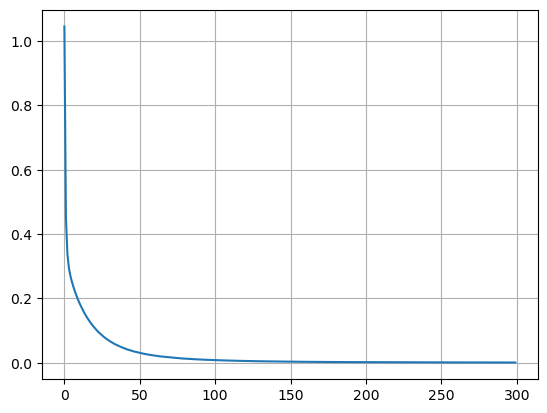

In [104]:
plt.plot(cost);
plt.grid();

In [52]:
activations[-1]

array([0.206, 0.223, 0.223, 0.414, 0.049, 0.598])

In [106]:
start = time.time()  
activations, weights, biases, cost_a = neural_network(inputs, outputs, [5], 1, 1, 1, 300, 1) 
end = time.time()
print("Time taken for 1 layer of 5 nodes:", end - start, "seconds")

start = time.time()  
activations, weights, biases, cost_b = neural_network(inputs, outputs, [5, 5], 1, 1, 1, 300, 1) 
end = time.time()
print("Time taken for 2 layes of 5 nodes:", end - start, "seconds")

start = time.time()  
activations, weights, biases, cost_c = neural_network(inputs, outputs, [5, 5, 5], 1, 1, 1, 300, 1) 
end = time.time()
print("Time taken for 3 layers of 5 nodes:", end - start, "seconds")

start = time.time()  
activations, weights, biases, cost_d = neural_network(inputs, outputs, [5, 5, 5, 5], 1, 1, 1, 300, 1) 
end = time.time()
print("Time taken for 4 layers of 5 nodes:", end - start, "seconds")

Time taken for 1 layer of 5 nodes: 0.9434549808502197 seconds
Time taken for 2 layes of 5 nodes: 2.0966830253601074 seconds
Time taken for 3 layers of 5 nodes: 7.1545610427856445 seconds
Time taken for 4 layers of 5 nodes: 35.28070116043091 seconds


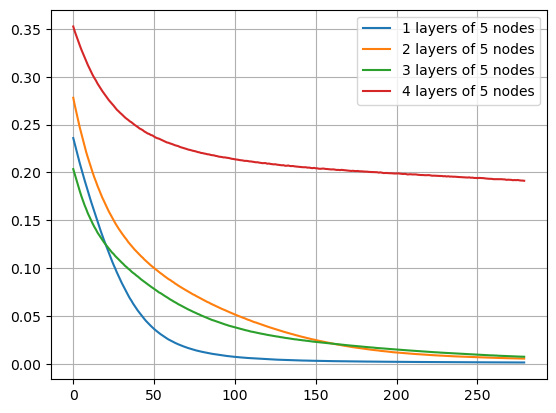

In [107]:
plt.plot(cost_a[20:], label="1 layers of 5 nodes");
plt.plot(cost_b[20:], label="2 layers of 5 nodes");
plt.plot(cost_c[20:], label="3 layers of 5 nodes");
plt.plot(cost_d[20:], label="4 layers of 5 nodes");
plt.grid();
plt.legend();

In [108]:
start = time.time()  
activations, weights, biases, cost_a = neural_network(inputs, outputs, [5], 1, 1, 1, 300, 0.5) 
end = time.time()
print("Time taken for 1 layer of 5 nodes:", end - start, "seconds")

start = time.time()  
activations, weights, biases, cost_b = neural_network(inputs, outputs, [5, 5], 1, 1, 1, 300, 0.5) 
end = time.time()
print("Time taken for 2 layes of 5 nodes:", end - start, "seconds")

start = time.time()  
activations, weights, biases, cost_c = neural_network(inputs, outputs, [5, 5, 5], 1, 1, 1, 300, 0.5) 
end = time.time()
print("Time taken for 3 layers of 5 nodes:", end - start, "seconds")

start = time.time()  
activations, weights, biases, cost_d = neural_network(inputs, outputs, [5, 5, 5, 5], 1, 1, 1, 300, 0.5) 
end = time.time()
print("Time taken for 4 layers of 5 nodes:", end - start, "seconds")

Time taken for 1 layer of 5 nodes: 0.48043084144592285 seconds
Time taken for 2 layes of 5 nodes: 1.0407681465148926 seconds
Time taken for 3 layers of 5 nodes: 3.9564871788024902 seconds
Time taken for 4 layers of 5 nodes: 17.216654777526855 seconds


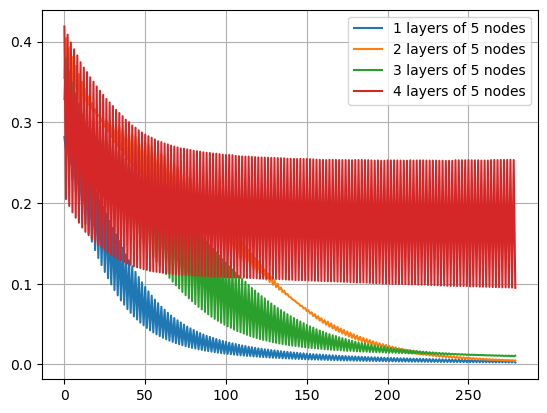

In [109]:
plt.plot(cost_a[20:], label="1 layers of 5 nodes");
plt.plot(cost_b[20:], label="2 layers of 5 nodes");
plt.plot(cost_c[20:], label="3 layers of 5 nodes");
plt.plot(cost_d[20:], label="4 layers of 5 nodes");
plt.grid();
plt.legend();

Time taken for 1 layer of 8 nodes: 0.9840390682220459 seconds
Time taken for 2 layes of 8 nodes: 2.3410730361938477 seconds
Time taken for 3 layers of 8 nodes: 12.755661010742188 seconds
Time taken for 4 layers of 8 nodes: 94.30621981620789 seconds


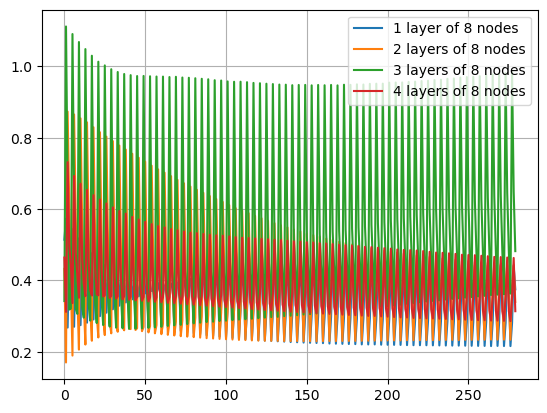

In [111]:
start = time.time()  
activations, weights, biases, cost_a = neural_network(inputs, outputs, [8], 1, 1, 1, 300, 0.75) 
end = time.time()
print("Time taken for 1 layer of 8 nodes:", end - start, "seconds")

start = time.time()  
activations, weights, biases, cost_b = neural_network(inputs, outputs, [8, 8], 1, 1, 1, 300, 0.75) 
end = time.time()
print("Time taken for 2 layes of 8 nodes:", end - start, "seconds")

start = time.time()  
activations, weights, biases, cost_c = neural_network(inputs, outputs, [8, 8, 8], 1, 1, 1, 300, 0.75) 
end = time.time()
print("Time taken for 3 layers of 8 nodes:", end - start, "seconds")

start = time.time()  
activations, weights, biases, cost_d = neural_network(inputs, outputs, [8, 8, 8, 8], 1, 1, 1, 300, 0.75) 
end = time.time()
print("Time taken for 4 layers of 8 nodes:", end - start, "seconds")

#laatste 4: max_bias, max_weight, learning_rate, iterations

plt.plot(cost_a[20:], label="1 layer of 8 nodes");
plt.plot(cost_b[20:], label="2 layers of 8 nodes");
plt.plot(cost_c[20:], label="3 layers of 8 nodes");
plt.plot(cost_d[20:], label="4 layers of 8 nodes");
plt.grid();
plt.legend();

Time taken for 1 layer of 5 nodes: 6.42817497253418 seconds
Time taken for 2 layes of 5 nodes: 14.457362174987793 seconds
Time taken for 3 layers of 5 nodes: 48.62819194793701 seconds


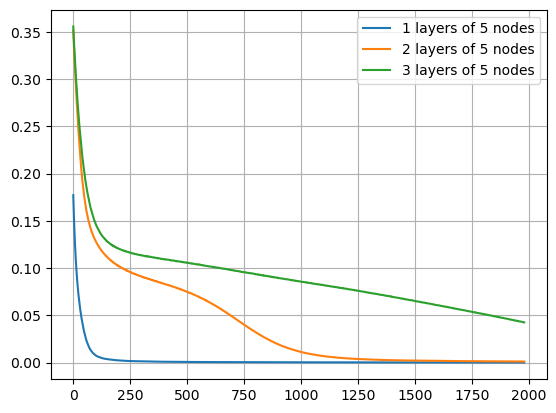

In [112]:
start = time.time()  
activations, weights, biases, cost_a = neural_network(inputs, outputs, [5], 1, 1, 1, 2000, 1) 
end = time.time()
print("Time taken for 1 layer of 5 nodes:", end - start, "seconds")

start = time.time()  
activations, weights, biases, cost_b = neural_network(inputs, outputs, [5, 5], 1, 1, 1, 2000, 1) 
end = time.time()
print("Time taken for 2 layes of 5 nodes:", end - start, "seconds")

start = time.time()  
activations, weights, biases, cost_c = neural_network(inputs, outputs, [5, 5, 5], 1, 1, 1, 2000, 1) 
end = time.time()
print("Time taken for 3 layers of 5 nodes:", end - start, "seconds")

plt.plot(cost_a[20:], label="1 layers of 5 nodes");
plt.plot(cost_b[20:], label="2 layers of 5 nodes");
plt.plot(cost_c[20:], label="3 layers of 5 nodes");
plt.grid();
plt.legend();

In [114]:
test_data = pd.read_csv("/Users/janvancauwenberghe/Desktop/DATA/eigen-projecten/neural-networks/mnist_test.csv")
train_data = pd.read_csv("/Users/janvancauwenberghe/Desktop/DATA/eigen-projecten/neural-networks/mnist_train.csv")

In [154]:
X_train = train_data.drop('label', axis=1).to_numpy()/255
y_train = pd.get_dummies(train_data['label']).astype(int).to_numpy()

X_test = test_data.drop('label', axis=1).to_numpy()/255
y_test = test_data['label']

In [135]:
X_train

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]])

In [136]:
y_train

array([[0, 0, 0, ..., 0, 0, 0],
       [1, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 1, 0]])

In [137]:
train_data['label'].head()

0    5
1    0
2    4
3    1
4    9
Name: label, dtype: int64

In [138]:
X_train.shape

(60000, 784)

In [139]:
y_train.shape

(60000, 10)

In [140]:
X_train.max()

1.0

Time taken for 1 layer of 16 nodes: 771.9477250576019 seconds


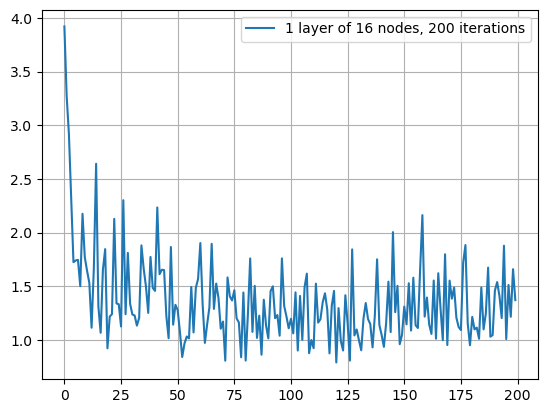

In [209]:
start = time.time()  
activations, weights_1, biases_1, cost_1 = neural_network(X_train, y_train, [16], 1, 1, 1, 200, 0.001) 
end = time.time()

print("Time taken for 1 layer of 16 nodes:", end - start, "seconds")

plt.plot(cost, label="1 layer of 16 nodes, 200 iterations");
plt.grid();
plt.legend();

Time taken for 2 layers of 16 nodes: 919.0639517307281 seconds


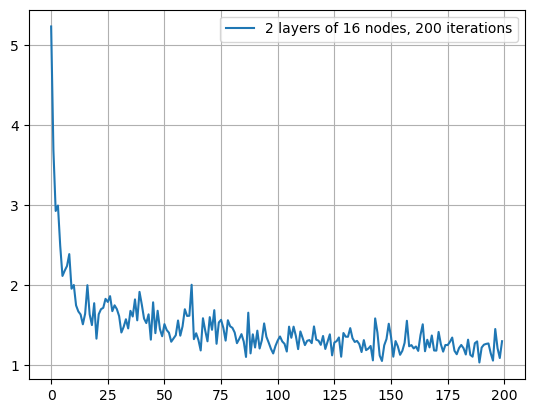

In [152]:
start = time.time()  
activations, weights_2, biases_2, cost_2 = neural_network(X_train, y_train, [16, 16], 1, 1, 1, 200, 0.001) 
end = time.time()

print("Time taken for 2 layers of 16 nodes:", end - start, "seconds")

plt.plot(cost_2, label="2 layers of 16 nodes, 200 iterations");
plt.grid();
plt.legend();

Time taken: 1286.881087064743 seconds


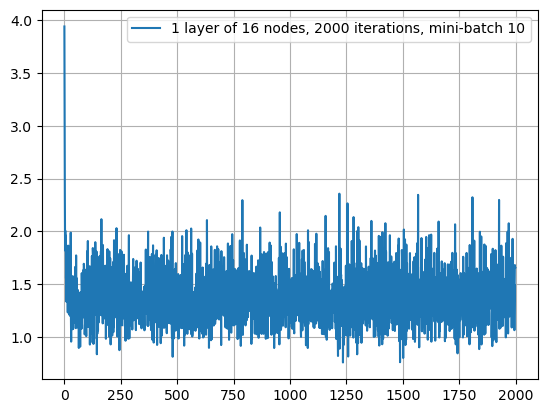

In [211]:
start = time.time()  
activations, weights_3, biases_3, cost_3 = neural_network(X_train, y_train, [16], 1, 1, 1, 2000, 1/6000) 
end = time.time()

print("Time taken:", end - start, "seconds")

plt.plot(cost_3, label="1 layer of 16 nodes, 2000 iterations, mini-batch 10");
plt.grid();
plt.legend();

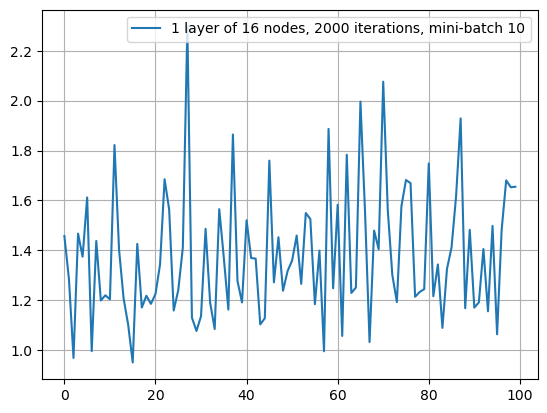

In [212]:
plt.plot(cost_3[-100:], label="1 layer of 16 nodes, 2000 iterations, mini-batch 10");
plt.grid();
plt.legend();

In [155]:
y_test

0       7
1       2
2       1
3       0
4       4
       ..
9995    2
9996    3
9997    4
9998    5
9999    6
Name: label, Length: 10000, dtype: int64

In [157]:
def predict(inputs, weights, biases, labels):

    outputs = []

    for i in range(len(inputs)):

        activations = det_activations(inputs[i], weights, biases)
        outputs.append(labels[np.argmax(activations[-1])])

    return outputs

In [158]:
labels = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

In [176]:
y_predict_1 = predict(X_test, weights_1, biases_1, labels)

In [167]:
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay, classification_report

In [177]:
accuracy_score(y_test,y_predict_1)

0.0957

In [169]:
#cm = confusion_matrix(y_test, y_predict, labels=labels, normalize='all')
#disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels);
#disp.plot()
#plt.show()

In [210]:
y_predict_2 = predict(X_test, weights_2, biases_2, labels)
accuracy_score(y_test,y_predict_2)

0.0957

In [182]:
y_test[:10]

0    7
1    2
2    1
3    0
4    4
5    1
6    4
7    9
8    5
9    9
Name: label, dtype: int64

In [184]:
y_predict_1[:10]

[1, 6, 6, 0, 7, 8, 8, 3, 8, 0]

In [186]:
y_predict_2[:10]

[1, 1, 6, 1, 1, 1, 1, 1, 5, 1]

In [193]:
y_train_nd[:10]

0    5
1    0
2    4
3    1
4    9
5    2
6    1
7    3
8    1
9    4
Name: label, dtype: int64

In [190]:
y_predict_3 = predict(X_train, weights_1, biases_1, labels)
y_predict_3[:10]

[8, 0, 5, 4, 1, 0, 1, 6, 1, 8]

In [191]:
y_predict_4 = predict(X_train, weights_2, biases_2, labels)
y_predict_4[:10]

[1, 1, 6, 1, 5, 1, 1, 1, 1, 6]

In [194]:
accuracy_score(y_train_nd,y_predict_3)

0.09603333333333333

In [195]:
accuracy_score(y_train_nd,y_predict_4)

0.0976